Célula 1: Importações e Criação da Massa de Dados (transacoes.csv)

In [9]:
import csv
import json
from datetime import datetime
import matplotlib.pyplot as plt
import numpy as np

# Constante global definida conforme o requisito do projeto

LIMITE_SUSPEITO = 10000.00

# Estrutura do arquivo transacoes.csv

transacoes = [
    # VÁLIDOS (Janeiro)

    {"id": "1", "data": "2026-01-05", "cliente_id": "CLI001", "tipo": "credito", "valor": "3500.00", "descricao": "Salario", "categoria": "salario"},
    {"id": "2", "data": "2026-01-12", "cliente_id": "CLI002", "tipo": "debito", "valor": "180.50", "descricao": "Mercado", "categoria": "compra"},
    {"id": "3", "data": "2026-01-15", "cliente_id": "CLI003", "tipo": "credito", "valor": "12000.00", "descricao": "Venda Carro", "categoria": "transferencia"}, # > 10k
    {"id": "4", "data": "2026-01-22", "cliente_id": "CLI001", "tipo": "debito", "valor": "350.00", "descricao": "Luz", "categoria": "conta"},
    {"id": "5", "data": "2026-01-28", "cliente_id": "CLI004", "tipo": "credito", "valor": "500.00", "descricao": "Pix", "categoria": "transferencia"},

    # VÁLIDOS (Fevereiro)

    {"id": "6", "data": "2026-02-01", "cliente_id": "CLI002", "tipo": "credito", "valor": "4000.00", "descricao": "Freelance", "categoria": "salario"},
    {"id": "7", "data": "2026-02-10", "cliente_id": "CLI003", "tipo": "debito", "valor": "1500.00", "descricao": "Aluguel", "categoria": "moradia"},
    {"id": "8", "data": "2026-02-14", "cliente_id": "CLI001", "tipo": "credito", "valor": "15000.00", "descricao": "Investimento", "categoria": "investimento"}, # > 10k
    {"id": "9", "data": "2026-02-20", "cliente_id": "CLI005", "tipo": "debito", "valor": "80.00", "descricao": "Farmacia", "categoria": "saude"},
    {"id": "10", "data": "2026-02-25", "cliente_id": "CLI002", "tipo": "debito", "valor": "220.00", "descricao": "Internet", "categoria": "conta"},

    # VÁLIDOS (Março)

    {"id": "11", "data": "2026-03-02", "cliente_id": "CLI001", "tipo": "credito", "valor": "3500.00", "descricao": "Salario", "categoria": "salario"},
    {"id": "12", "data": "2026-03-10", "cliente_id": "CLI004", "tipo": "debito", "valor": "99.90", "descricao": "Streaming", "categoria": "assinatura"},
    {"id": "13", "data": "2026-03-15", "cliente_id": "CLI003", "tipo": "debito", "valor": "450.00", "descricao": "Mercado", "categoria": "compra"},
    {"id": "14", "data": "2026-03-20", "cliente_id": "CLI005", "tipo": "credito", "valor": "1200.00", "descricao": "Restituição", "categoria": "outros"},
    {"id": "15", "data": "2026-03-28", "cliente_id": "CLI002", "tipo": "debito", "valor": "310.00", "descricao": "Combustivel", "categoria": "transporte"},

    # INVÁLIDOS (5 registros para testar a validação)

    {"id": "16", "data": "2026-03-29", "cliente_id": "CLI001", "tipo": "credito", "valor": "abc", "descricao": "Valor texto", "categoria": "erro"}, # valor não numérico
    {"id": "17", "data": "2026-03-30", "cliente_id": "", "tipo": "debito", "valor": "100.00", "descricao": "Sem cliente", "categoria": "erro"}, # cliente_id vazio
    {"id": "18", "data": "15/04/2026", "cliente_id": "CLI002", "tipo": "credito", "valor": "200.00", "descricao": "Data formato BR", "categoria": "erro"}, # data inválida
    {"id": "19", "data": "2026-04-02", "cliente_id": "CLI003", "tipo": "pix", "valor": "150.00", "descricao": "Tipo invalido", "categoria": "erro"}, # tipo inválido
    {"id": "", "data": "2026-04-05", "cliente_id": "CLI004", "tipo": "debito", "valor": "80.00", "descricao": "ID vazio", "categoria": "erro"} # ID vazio
]

campos = ["id", "data", "cliente_id", "tipo", "valor", "descricao", "categoria"]

with open("transacoes.csv", mode="w", newline="", encoding="utf-8") as arquivo:
    escritor = csv.DictWriter(arquivo, fieldnames=campos)
    escritor.writeheader()
    escritor.writerows(transacoes)

print("Arquivo transacoes.csv criado com sucesso!")

Arquivo transacoes.csv criado com sucesso!


Célula 2: Leitura



In [10]:
def ler_transacoes(caminho_arquivo):
    """
    Lê o arquivo CSV de transações e retorna a lista de transações brutas.
    Trata a exceção FileNotFoundError caso o arquivo não exista no disco.
    """

    transacoes_brutas = []

    # Tratamento de erro caso o arquivo CSV não exista no disco

    try:
        with open(caminho_arquivo, mode="r", encoding="utf-8") as arquivo:
            leitor = csv.DictReader(arquivo)
            for linha in leitor:
                transacoes_brutas.append(linha)
    except FileNotFoundError:
        print(f"Erro: O arquivo '{caminho_arquivo}' não foi encontrado no sistema.")
        return []

    return transacoes_brutas


# Teste da função ler_transacoes na própria célula

brutas = ler_transacoes("transacoes.csv")

print(f"Total de transações brutas lidas do CSV: {len(brutas)}")

Total de transações brutas lidas do CSV: 20


Célula 3: Validação



In [11]:
def validar_transacao(linha):
    """
    Valida uma única linha do CSV.
    Retorna o dicionário com os dados limpos se for válida, ou None se for inválida.
    """

    # Captura de exceções e validação dos campos obrigatórios e formatos

    try:

        # Validação do ID (não pode ser vazio e deve ser numérico)

        id_str = (linha.get("id") or "").strip()
        if not id_str or not id_str.isdigit():
            return None
        id_val = int(id_str)

        # Validação do cliente_id (não pode ser vazio)

        cliente_id = (linha.get("cliente_id") or "").strip()
        if not cliente_id:
            return None

        # Validação do tipo (deve ser estritamente 'credito' ou 'debito')

        tipo = (linha.get("tipo") or "").strip().lower()

        if tipo not in ["credito", "debito"]:
            return None

        # Validação da data com datetime.strptime (formato AAAA-MM-DD)

        data_str = (linha.get("data") or "").strip()
        data_obj = datetime.strptime(data_str, "%Y-%m-%d")

        # Validação do valor com conversão float (deve ser maior que zero)

        valor_str = (linha.get("valor") or "").strip()
        valor = float(valor_str)
        if valor <= 0:
            return None

        # Retorno do registro limpo e convertido

        return {
            "id": id_val,
            "data": data_str,
            "data_obj": data_obj,
            "cliente_id": cliente_id,
            "tipo": tipo,
            "valor": valor,
            "descricao": (linha.get("descricao") or "").strip(),
            "categoria": (linha.get("categoria") or "").strip()
        }

    # Captura de erros de conversão de tipo, valores inválidos ou campos ausentes
    except (ValueError, TypeError, AttributeError):
        return None


def processar_validacao(transacoes_brutas):
    """
    Recebe a lista de transações brutas, valida cada linha e retorna um dicionário
    contendo os registros válidos e os totais de controle.
    """

    validas = []
    total_invalidas = 0

    # Iteração sobre as linhas brutas utilizando validar_transacao

    for linha in transacoes_brutas:
        registro = validar_transacao(linha)
        if registro:
            validas.append(registro)
        else:
            total_invalidas += 1

    total_lidas = len(validas) + total_invalidas

    # Estrutura padronizada para reutilização nas próximas células

    return {
        "transacoes_validas": validas,
        "total_lidas": total_lidas,
        "total_validas": len(validas),
        "total_invalidas": total_invalidas
    }


# Teste da Célula 3 reutilizando os métodos das Células 2 e 3

brutas = ler_transacoes("transacoes.csv")

resultado_validacao = processar_validacao(brutas)

print(f"Linhas lidas: {resultado_validacao['total_lidas']} | "
      f"Válidas: {resultado_validacao['total_validas']} | "
      f"Inválidas: {resultado_validacao['total_invalidas']}")

Linhas lidas: 20 | Válidas: 15 | Inválidas: 5


Célula 4: Geração de Relatório

In [12]:
def gerar_relatorio(transacoes_validas):
    """
    Recebe a lista de transações válidas, realiza o agrupamento mensal (AAAA-MM),
    calcula as métricas financeiras, determina o intervalo de dias analisado e
    filtra as transações suspeitas (valor > LIMITE_SUSPEITO).
    """

    if not transacoes_validas:

        return {
            "periodo": {"inicio": None, "fim": None, "dias": 0},
            "resumo_mensal": {},
            "transacoes_suspeitas": []
        }

    # Ordenação por data para identificar a transação mais antiga e a mais recente

    transacoes_ordenadas = sorted(transacoes_validas, key=lambda x: x["data_obj"])
    data_antiga = transacoes_ordenadas[0]["data_obj"]
    data_recente = transacoes_ordenadas[-1]["data_obj"]
    dias_totais = (data_recente - data_antiga).days

    # Estruturas para agrupamento mensal e filtragem de suspeitas

    resumo_mensal = {}
    transacoes_suspeitas = []

    # Iteração para agrupar transações e identificar movimentações suspeitas

    for t in transacoes_validas:

        # Identificação de transações com valor acima do limite suspeito (R$ 10.000,00)

        if t["valor"] > LIMITE_SUSPEITO:
            transacoes_suspeitas.append({
                "id": t["id"],
                "cliente_id": t["cliente_id"],
                "data": t["data"],
                "valor": t["valor"]
            })

        # Extração do mês no formato AAAA-MM

        mes = t["data"][:7]

        if mes not in resumo_mensal:
            resumo_mensal[mes] = {
                "quantidade": 0,
                "total_credito": 0.0,
                "total_debito": 0.0,
                "valores": []
            }

        resumo_mensal[mes]["quantidade"] += 1
        resumo_mensal[mes]["valores"].append(t["valor"])

        if t["tipo"] == "credito":
            resumo_mensal[mes]["total_credito"] += t["valor"]
        elif t["tipo"] == "debito":
            resumo_mensal[mes]["total_debito"] += t["valor"]

    # Consolidação das métricas finais por mês

    resumo_consolidado = {}

    for mes, dados in sorted(resumo_mensal.items()):
        total_cred = dados["total_credito"]
        total_deb = dados["total_debito"]
        valores = dados["valores"]

        resumo_consolidado[mes] = {
            "quantidade": dados["quantidade"],
            "total_credito": round(total_cred, 2),
            "total_debito": round(total_deb, 2),
            "saldo": round(total_cred - total_deb, 2),
            "media": round(sum(valores) / len(valores), 2),
            "maior_valor": round(max(valores), 2),
            "menor_valor": round(min(valores), 2)
        }

    return {
        "periodo": {
            "inicio": data_antiga.strftime("%Y-%m-%d"),
            "fim": data_recente.strftime("%Y-%m-%d"),
            "dias": dias_totais
        },
        "resumo_mensal": resumo_consolidado,
        "transacoes_suspeitas": transacoes_suspeitas
    }


# Teste da Célula 4 reutilizando as funções anteriores

brutas = ler_transacoes("transacoes.csv")
validacao = processar_validacao(brutas)
relatorio = gerar_relatorio(validacao["transacoes_validas"])

print(f"Período analisado: {relatorio['periodo']['inicio']} a {relatorio['periodo']['fim']} ({relatorio['periodo']['dias']} dias)")
print(f"Meses agrupados: {list(relatorio['resumo_mensal'].keys())}")
print(f"Transações suspeitas encontradas: {len(relatorio['transacoes_suspeitas'])}")

Período analisado: 2026-01-05 a 2026-03-28 (82 dias)
Meses agrupados: ['2026-01', '2026-02', '2026-03']
Transações suspeitas encontradas: 2


Célula 5: Geração do Relatório em JSON

In [13]:
def salvar_json(dados_relatorio, caminho_arquivo="relatorio.json"):
    """
    Recebe o dicionário consolidado do relatório e salva no arquivo físico
    relatorio.json utilizando json.dump com indentação e codificação UTF-8.
    """

    # Tratamento de exceção para operações de escrita de arquivo (I/O)

    try:
        with open(caminho_arquivo, mode="w", encoding="utf-8") as arquivo:
            json.dump(dados_relatorio, arquivo, indent=2, ensure_ascii=False)

        print(f"Arquivo '{caminho_arquivo}' gerado com sucesso!")
        return True
    except IOError as e:
        print(f"Erro ao salvar o arquivo JSON: {e}")
        return False


# Teste da Célula 5 reutilizando os dados das células anteriores

brutas = ler_transacoes("transacoes.csv")
validacao = processar_validacao(brutas)
relatorio = gerar_relatorio(validacao["transacoes_validas"])

# Montagem da estrutura final exigida para a exportação JSON incluindo transações suspeitas

dados_para_json = {
    "gerado_em": datetime.now().strftime("%Y-%m-%d"),
    "total_transacoes_validas": validacao["total_validas"],
    "total_transacoes_invalidas": validacao["total_invalidas"],
    "resumo_mensal": relatorio["resumo_mensal"],
    "transacoes_suspeitas": relatorio["transacoes_suspeitas"]
}

# Teste de execução da função de salvamento em disco

salvar_json(dados_para_json, "relatorio.json")

Arquivo 'relatorio.json' gerado com sucesso!


True

Célula 6: Exibição de Relatório

In [14]:
def formatar_moeda(valor):
    """
    Formata um valor numérico float para o padrão monetário brasileiro (R$ 1.234,56).
    """

    return f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")


def exibir_relatorio(dados_validacao, dados_relatorio):
    """
    Formata e exibe no terminal o relatório financeiro completo com separadores visuais,
    resumo de limpeza, período analisado, métricas mensais e transações suspeitas.
    """

    # Exibição do resumo da leitura e validação do CSV

    print("===== RESUMO DA LEITURA E LIMPEZA =====")
    print(f"Total de linhas lidas: {dados_validacao['total_lidas']}")
    print(f"Linhas válidas:        {dados_validacao['total_validas']}")
    print(f"Linhas inválidas:      {dados_validacao['total_invalidas']}")
    print()

    # Exibição do período total analisado

    periodo = dados_relatorio.get("periodo", {})

    print("===== PERÍODO ANALISADO =====")
    if periodo.get("inicio") and periodo.get("fim"):
        print(f"De: {periodo['inicio']} até {periodo['fim']} ({periodo['dias']} dias de intervalo)")
    else:
        print("Nenhum período disponível.")
    print()

    # Exibição das métricas financeiras agrupadas por mês

    print("===== RELATÓRIO MENSAL =====")
    resumo_mensal = dados_relatorio.get("resumo_mensal", {})

    if not resumo_mensal:
        print("Nenhum dado mensal para exibir.")
    else:
        for mes, metricas in resumo_mensal.items():
            print(f"Mês: {mes}")
            print(f"  Transações:    {metricas['quantidade']}")
            print(f"  Total crédito: {formatar_moeda(metricas['total_credito'])}")
            print(f"  Total débito:  {formatar_moeda(metricas['total_debito'])}")
            print(f"  Saldo:         {formatar_moeda(metricas['saldo'])}")
            print(f"  Média:         {formatar_moeda(metricas['media'])}")
            print(f"  Maior valor:   {formatar_moeda(metricas['maior_valor'])}")
            print(f"  Menor valor:   {formatar_moeda(metricas['menor_valor'])}")
            print()

    # Exibição da lista de transações potencialmente suspeitas (> R$ 10.000,00)

    print("===== TRANSAÇÕES SUSPEITAS =====")
    suspeitas = dados_relatorio.get("transacoes_suspeitas", [])

    if not suspeitas:
        print("Nenhuma transação suspeita encontrada.")
    else:
        for s in suspeitas:
            valor_fmt = formatar_moeda(s['valor'])
            print(f"ID: {s['id']} | Cliente: {s['cliente_id']} | Data: {s['data']} | Valor: {valor_fmt}")
    print()


# Teste da Célula 6 utilizando o fluxo das células anteriores

brutas = ler_transacoes("transacoes.csv")
validacao = processar_validacao(brutas)
relatorio = gerar_relatorio(validacao["transacoes_validas"])
exibir_relatorio(validacao, relatorio)

===== RESUMO DA LEITURA E LIMPEZA =====
Total de linhas lidas: 20
Linhas válidas:        15
Linhas inválidas:      5

===== PERÍODO ANALISADO =====
De: 2026-01-05 até 2026-03-28 (82 dias de intervalo)

===== RELATÓRIO MENSAL =====
Mês: 2026-01
  Transações:    5
  Total crédito: R$ 16.000,00
  Total débito:  R$ 530,50
  Saldo:         R$ 15.469,50
  Média:         R$ 3.306,10
  Maior valor:   R$ 12.000,00
  Menor valor:   R$ 180,50

Mês: 2026-02
  Transações:    5
  Total crédito: R$ 19.000,00
  Total débito:  R$ 1.800,00
  Saldo:         R$ 17.200,00
  Média:         R$ 4.160,00
  Maior valor:   R$ 15.000,00
  Menor valor:   R$ 80,00

Mês: 2026-03
  Transações:    5
  Total crédito: R$ 4.700,00
  Total débito:  R$ 859,90
  Saldo:         R$ 3.840,10
  Média:         R$ 1.111,98
  Maior valor:   R$ 3.500,00
  Menor valor:   R$ 99,90

===== TRANSAÇÕES SUSPEITAS =====
ID: 3 | Cliente: CLI003 | Data: 2026-01-15 | Valor: R$ 12.000,00
ID: 8 | Cliente: CLI001 | Data: 2026-02-14 | Valor: R$ 1

Célula 7: Execução Principal

In [15]:
def main():
    """
    Função principal de execução do pipeline completo de análise financeira.
    Orquestra a leitura do CSV, validação dos dados, geração de métricas,
    exibição do relatório no terminal e exportação do arquivo JSON final.
    """

    # 1. Leitura das transações brutas a partir do arquivo CSV

    transacoes_brutas = ler_transacoes("transacoes.csv")

    if not transacoes_brutas:
        print("Execução interrompida: Nenhuma transação encontrada ou falha ao abrir o arquivo.")
        return

    # 2. Processamento e validação das linhas brutas

    dados_validacao = processar_validacao(transacoes_brutas)

    # 3. Geração do relatório agrupado com métricas mensais

    dados_relatorio = gerar_relatorio(dados_validacao["transacoes_validas"])

    # 4. Exibição do relatório formatado no terminal

    exibir_relatorio(dados_validacao, dados_relatorio)

    # 5. Estruturação e exportação do relatório consolidado em JSON

    dados_para_json = {
        "gerado_em": datetime.now().strftime("%Y-%m-%d"),
        "total_transacoes_validas": dados_validacao["total_validas"],
        "total_transacoes_invalidas": dados_validacao["total_invalidas"],
        "resumo_mensal": dados_relatorio["resumo_mensal"],
        "transacoes_suspeitas": dados_relatorio["transacoes_suspeitas"]
    }

    salvar_json(dados_para_json, "relatorio.json")


# Execução do pipeline principal

if __name__ == "__main__":
    main()

===== RESUMO DA LEITURA E LIMPEZA =====
Total de linhas lidas: 20
Linhas válidas:        15
Linhas inválidas:      5

===== PERÍODO ANALISADO =====
De: 2026-01-05 até 2026-03-28 (82 dias de intervalo)

===== RELATÓRIO MENSAL =====
Mês: 2026-01
  Transações:    5
  Total crédito: R$ 16.000,00
  Total débito:  R$ 530,50
  Saldo:         R$ 15.469,50
  Média:         R$ 3.306,10
  Maior valor:   R$ 12.000,00
  Menor valor:   R$ 180,50

Mês: 2026-02
  Transações:    5
  Total crédito: R$ 19.000,00
  Total débito:  R$ 1.800,00
  Saldo:         R$ 17.200,00
  Média:         R$ 4.160,00
  Maior valor:   R$ 15.000,00
  Menor valor:   R$ 80,00

Mês: 2026-03
  Transações:    5
  Total crédito: R$ 4.700,00
  Total débito:  R$ 859,90
  Saldo:         R$ 3.840,10
  Média:         R$ 1.111,98
  Maior valor:   R$ 3.500,00
  Menor valor:   R$ 99,90

===== TRANSAÇÕES SUSPEITAS =====
ID: 3 | Cliente: CLI003 | Data: 2026-01-15 | Valor: R$ 12.000,00
ID: 8 | Cliente: CLI001 | Data: 2026-02-14 | Valor: R$ 1

Célula 8: Visualização com Matplotlib

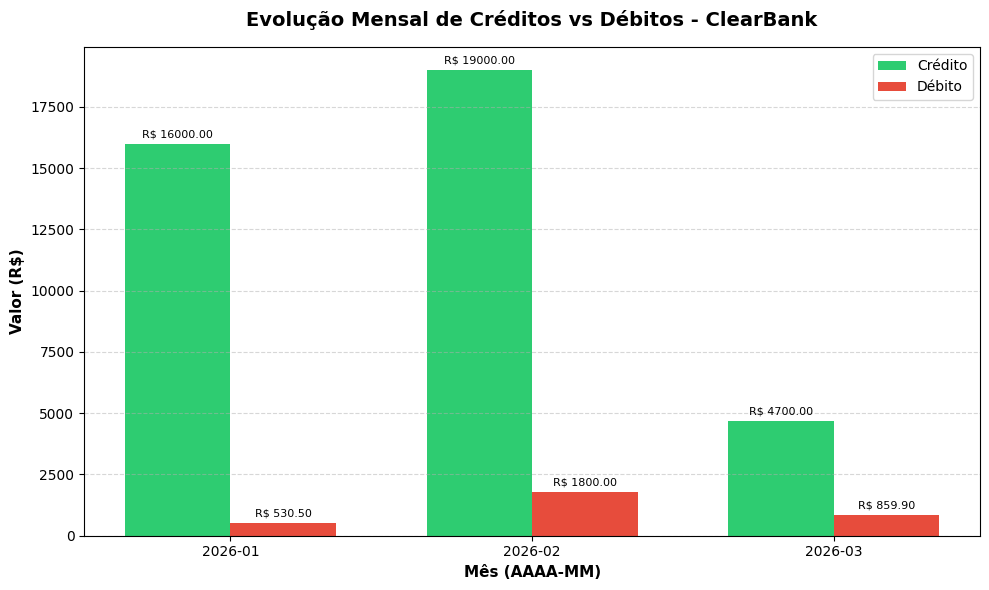

Gráfico 'grafico.png' gerado e salvo com sucesso!


In [16]:
# Execução do pipeline para obter os dados agrupados do relatório

brutas = ler_transacoes("transacoes.csv")
validacao = processar_validacao(brutas)
relatorio = gerar_relatorio(validacao["transacoes_validas"])
resumo_mensal = relatorio.get("resumo_mensal", {})

# Extração dos dados para os eixos do gráfico

meses = list(resumo_mensal.keys())
creditos = [resumo_mensal[mes]["total_credito"] for mes in meses]
debitos = [resumo_mensal[mes]["total_debito"] for mes in meses]
saldos = [resumo_mensal[mes]["saldo"] for mes in meses]

# Configuração da figura e alinhamento das barras duplas

indices = np.arange(len(meses))
largura_barra = 0.35
fig, ax = plt.subplots(figsize=(10, 6))

# Construção das barras de Crédito e Débito

barras_credito = ax.bar(indices - largura_barra/2, creditos, largura_barra, label="Crédito", color="#2ecc71")
barras_debito = ax.bar(indices + largura_barra/2, debitos, largura_barra, label="Débito", color="#e74c3c")

# Personalização de títulos, rótulos e eixos

ax.set_title("Evolução Mensal de Créditos vs Débitos - ClearBank", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Mês (AAAA-MM)", fontsize=11, fontweight="bold")
ax.set_ylabel("Valor (R$)", fontsize=11, fontweight="bold")
ax.set_xticks(indices)
ax.set_xticklabels(meses)
ax.legend(fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.5)

# Adição dos valores acima das barras para melhor leitura

ax.bar_label(barras_credito, padding=3, fmt="R$ %.2f", fontsize=8)
ax.bar_label(barras_debito, padding=3, fmt="R$ %.2f", fontsize=8)
plt.tight_layout()

# Salvamento do arquivo grafico.png e exibição no notebook

plt.savefig("grafico.png", dpi=300, bbox_inches="tight")
plt.show()
print("Gráfico 'grafico.png' gerado e salvo com sucesso!")